C:\Users\adity\AppData\Local\Temp\ipykernel_21088\2686282510.py:52: RuntimeWarning: invalid value encountered in power
  months < 10, 0.98, 0.98 + 0.02 * (months - 9) ** 1.2
C:\Users\adity\AppData\Local\Temp\ipykernel_21088\2686282510.py:55: RuntimeWarning: invalid value encountered in power
  months < 10, 0.97, 0.97 - 0.015 * (months - 9) ** 1.1


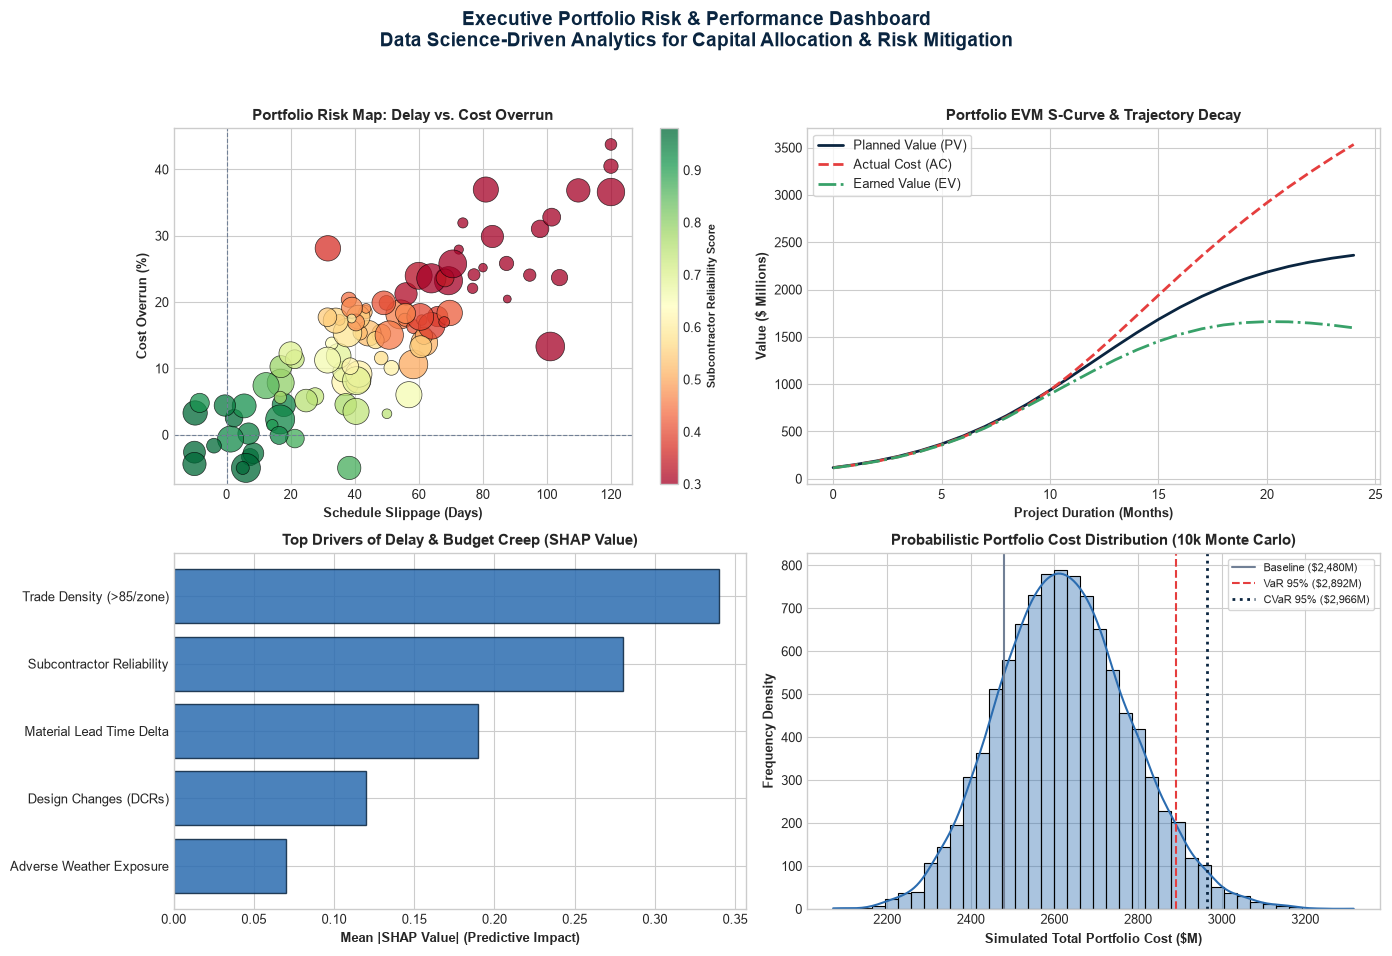

[SUCCESS] Executive dashboard generated and exported as 'executive_construction_dashboard.png'.


In [1]:
"""
Week 4: Executive Data Visualization & Stakeholder Reporting Dashboard
Construction Project Performance Analytics
"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Styling configuration
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 9
plt.rcParams["axes.labelweight"] = "bold"

NAVY = "#0A2540"
BLUE = "#2B6CB0"
RED = "#E53E3E"
GREEN = "#38A169"
GRAY = "#718096"

np.random.seed(42)

# --- 1. Synthesize Data Points ---
n_projects = 100
budget = np.random.uniform(10, 150, n_projects)  # $M
cost_overrun_pct = np.clip(np.random.normal(14.2, 12.0, n_projects), -5.0, 50.0)
schedule_delay_days = np.clip(
    cost_overrun_pct * 2.5 + np.random.normal(10, 15, n_projects), -10, 120
)
reliability_score = np.clip(
    1.0
    - (cost_overrun_pct / 60.0)
    - (schedule_delay_days / 200.0)
    + np.random.normal(0, 0.05, n_projects),
    0.30,
    0.98,
)

# S-Curve Data
months = np.arange(0, 25)
planned_value = 2480 * (1 / (1 + np.exp(-0.25 * (months - 12))))
actual_cost = planned_value * np.where(
    months < 10, 0.98, 0.98 + 0.02 * (months - 9) ** 1.2
)
earned_value = planned_value * np.where(
    months < 10, 0.97, 0.97 - 0.015 * (months - 9) ** 1.1
)

# SHAP Feature Importance
features = [
    "Trade Density (>85/zone)",
    "Subcontractor Reliability",
    "Material Lead Time Delta",
    "Design Changes (DCRs)",
    "Adverse Weather Exposure",
]
shap_values = [0.34, 0.28, 0.19, 0.12, 0.07]

# Monte Carlo (10,000 Iterations)
baseline_portfolio_cost = 2480
simulated_costs = np.random.lognormal(
    mean=np.log(2620), sigma=0.06, size=10000
)
var_95 = np.percentile(simulated_costs, 95)
cvar_95 = np.mean(simulated_costs[simulated_costs >= var_95])

# --- 2. Canvas & Plots ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor="white")
fig.suptitle(
    "Executive Portfolio Risk & Performance Dashboard\n"
    "Data Science-Driven Analytics for Capital Allocation & Risk Mitigation",
    fontsize=14,
    fontweight="bold",
    color=NAVY,
    y=0.98,
)

# Panel 1: Portfolio Risk Map
ax1 = axes[0, 0]
scatter = ax1.scatter(
    schedule_delay_days,
    cost_overrun_pct,
    s=budget * 3,
    c=reliability_score,
    cmap="RdYlGn",
    alpha=0.75,
    edgecolors="black",
    linewidth=0.5,
)
ax1.axhline(0, color=GRAY, linestyle="--", linewidth=0.8)
ax1.axvline(0, color=GRAY, linestyle="--", linewidth=0.8)
ax1.set_title("Portfolio Risk Map: Delay vs. Cost Overrun")
ax1.set_xlabel("Schedule Slippage (Days)")
ax1.set_ylabel("Cost Overrun (%)")
cbar = fig.colorbar(scatter, ax=ax1)
cbar.set_label("Subcontractor Reliability Score", fontsize=8)

# Panel 2: EVM S-Curve
ax2 = axes[0, 1]
ax2.plot(
    months, planned_value, label="Planned Value (PV)", color=NAVY, linewidth=2
)
ax2.plot(
    months,
    actual_cost,
    label="Actual Cost (AC)",
    color=RED,
    linewidth=2,
    linestyle="--",
)
ax2.plot(
    months,
    earned_value,
    label="Earned Value (EV)",
    color=GREEN,
    linewidth=2,
    linestyle="-.",
)
ax2.set_title("Portfolio EVM S-Curve & Trajectory Decay")
ax2.set_xlabel("Project Duration (Months)")
ax2.set_ylabel("Value ($ Millions)")
ax2.legend(loc="upper left", frameon=True)

# Panel 3: Feature Attribution (SHAP)
ax3 = axes[1, 0]
y_pos = np.arange(len(features))
ax3.barh(
    y_pos, shap_values, align="center", color=BLUE, alpha=0.85, edgecolor=NAVY
)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(features)
ax3.invert_yaxis()
ax3.set_title("Top Drivers of Delay & Budget Creep (SHAP Value)")
ax3.set_xlabel("Mean |SHAP Value| (Predictive Impact)")

# Panel 4: Monte Carlo Distribution
ax4 = axes[1, 1]
sns.histplot(simulated_costs, kde=True, ax=ax4, color=BLUE, alpha=0.4, bins=40)
ax4.axvline(
    baseline_portfolio_cost,
    color=GRAY,
    linestyle="-",
    linewidth=1.5,
    label=f"Baseline (${baseline_portfolio_cost:,}M)",
)
ax4.axvline(
    var_95,
    color=RED,
    linestyle="--",
    linewidth=1.5,
    label=f"VaR 95% (${var_95:,.0f}M)",
)
ax4.axvline(
    cvar_95,
    color=NAVY,
    linestyle=":",
    linewidth=2.0,
    label=f"CVaR 95% (${cvar_95:,.0f}M)",
)
ax4.set_title("Probabilistic Portfolio Cost Distribution (10k Monte Carlo)")
ax4.set_xlabel("Simulated Total Portfolio Cost ($M)")
ax4.set_ylabel("Frequency Density")
ax4.legend(loc="upper right", frameon=True, fontsize=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(
    "executive_construction_dashboard.png", dpi=300, bbox_inches="tight"
)
plt.show()
print(
    "[SUCCESS] Executive dashboard generated and exported as 'executive_construction_dashboard.png'."
)